# 초음파 광물 예측 데이터

- 1988년 존스홉킨스대학교의 세즈노프스키 교수가 1986년 힌튼 교수가 발표한 역전파 알고리즘에 관심을 갖고 은닉층과 역전파의 효과를 실험하기 위해 정리한 데이터

- 광석과 일반 돌에 각각 음파 탐지기를 쏜 후 그 결과를 정리

In [1]:
import pandas as pd
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
import missingno as msno

In [2]:
df = pd.read_csv("./data/sonar.csv", header = None)

In [3]:
df.head()

,0,1,2,3,4,5,6,7,8,9,...,51,52,53,54,55,56,57,58,59,60
0,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0027,0.0065,0.0159,0.0072,0.0167,0.0180,0.0084,0.0090,0.0032,R
1,0.0453,0.0523,0.0843,0.0689,0.1183,0.2583,0.2156,0.3481,0.3337,0.2872,...,0.0084,0.0089,0.0048,0.0094,0.0191,0.0140,0.0049,0.0052,0.0044,R
2,0.0262,0.0582,0.1099,0.1083,0.0974,0.2280,0.2431,0.3771,0.5598,0.6194,...,0.0232,0.0166,0.0095,0.0180,0.0244,0.0316,0.0164,0.0095,0.0078,R
3,0.0100,0.0171,0.0623,0.0205,0.0205,0.0368,0.1098,0.1276,0.0598,0.1264,...,0.0121,0.0036,0.0150,0.0085,0.0073,0.0050,0.0044,0.0040,0.0117,R
4,0.0762,0.0666,0.0481,0.0394,0.0590,0.0649,0.1209,0.2467,0.3564,0.4459,...,0.0031,0.0054,0.0105,0.0110,0.0015,0.0072,0.0048,0.0107,0.0094,R


In [4]:
df.shape

(208, 61)

In [5]:
df.describe()

,0,1,2,3,4,5,6,7,8,9,...,50,51,52,53,54,55,56,57,58,59
count,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,...,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000
mean,0.029164,0.038437,0.043832,0.053892,0.075202,0.104570,0.121747,0.134799,0.178003,0.208259,...,0.016069,0.013420,0.010709,0.010941,0.009290,0.008222,0.007820,0.007949,0.007941,0.006507
std,0.022991,0.032960,0.038428,0.046528,0.055552,0.059105,0.061788,0.085152,0.118387,0.134416,...,0.012008,0.009634,0.007060,0.007301,0.007088,0.005736,0.005785,0.006470,0.006181,0.005031
min,0.001500,0.000600,0.001500,0.005800,0.006700,0.010200,0.003300,0.005500,0.007500,0.011300,...,0.000000,0.000800,0.000500,0.001000,0.000600,0.000400,0.000300,0.000300,0.000100,0.000600
25%,0.013350,0.016450,0.018950,0.024375,0.038050,0.067025,0.080900,0.080425,0.097025,0.111275,...,0.008425,0.007275,0.005075,0.005375,0.004150,0.004400,0.003700,0.003600,0.003675,0.003100
50%,0.022800,0.030800,0.034300,0.044050,0.062500,0.092150,0.106950,0.112100,0.152250,0.182400,...,0.013900,0.011400,0.009550,0.009300,0.007500,0.006850,0.005950,0.005800,0.006400,0.005300
75%,0.035550,0.047950,0.057950,0.064500,0.100275,0.134125,0.154000,0.169600,0.233425,0.268700,...,0.020825,0.016725,0.014900,0.014500,0.012100,0.010575,0.010425,0.010350,0.010325,0.008525
max,0.137100,0.233900,0.305900,0.426400,0.401000,0.382300,0.372900,0.459000,0.682800,0.710600,...,0.100400,0.070900,0.039000,0.035200,0.044700,0.039400,0.035500,0.044000,0.036400,0.043900


In [6]:
df.isna().sum()

0     0
1     0
2     0
3     0
4     0
     ..
56    0
57    0
58    0
59    0
60    0
Length: 61, dtype: int64

<Axes: >

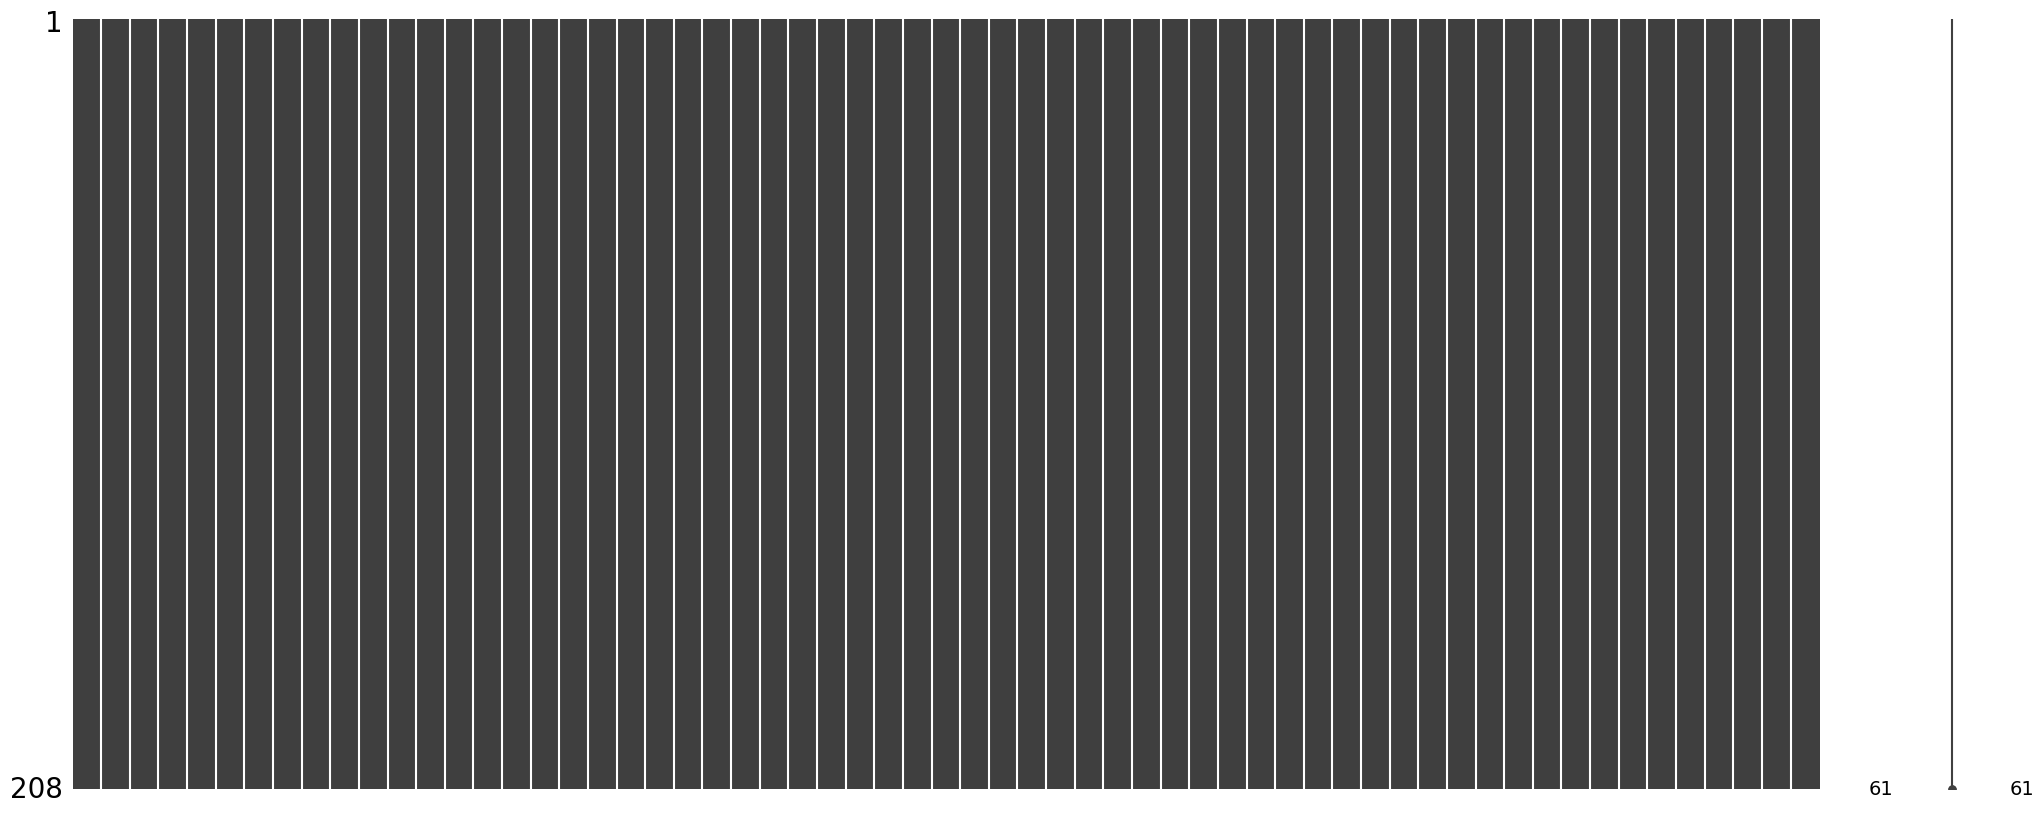

In [7]:
msno.matrix(df)

In [8]:
df[60].value_counts()

60
M    111
R     97
Name: count, dtype: int64

In [9]:
x = df.iloc[:, :-1]
y = df.iloc[:, -1]

# ver1(원핫인코딩 방식)

In [12]:
enc_y = pd.get_dummies(y, dtype = int)

In [13]:
enc_y.head()

,M,R
0,0,1
1,0,1
2,0,1
3,0,1
4,0,1


In [14]:
# 데이터 분할
x_train, x_test, y_train, y_test = train_test_split(x, enc_y, test_size = 0.2, stratify = enc_y,
                                                    random_state = 26)

In [15]:
x_sub, x_val, y_sub, y_val = train_test_split(x_train, y_train, test_size = 0.2, stratify = y_train,
                                              random_state = 26)

In [16]:
x_sub.shape, x_val.shape, x_test.shape

((132, 60), (34, 60), (42, 60))

In [18]:
# 스케일링
mm = MinMaxScaler()
scaled_sub = mm.fit_transform(x_sub)
scaled_val = mm.transform(x_val)
scaled_test = mm.transform(x_test)

In [24]:
# 모델링
model = keras.Sequential()
model.add(keras.Input(shape = (60,))) # 입력층
model.add(keras.layers.Dense(64, activation = "relu")) # 은닉층
model.add(keras.layers.Dense(32, activation = "relu"))
model.add(keras.layers.Dense(2, activation = "softmax")) # 출력층

In [25]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                      │ (None, 64)                  │           3,904 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 2)                   │              66 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 6,050 (23.63 KB)

 Trainable params: 6,050 (23.63 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
model.compile(loss = "categorical_crossentropy", optimizer = "adam", metrics = ["accuracy"])

In [27]:
es_cb = keras.callbacks.EarlyStopping(patience = 8, restore_best_weights = True)

In [28]:
model.fit(scaled_sub, y_sub, epochs = 200, batch_size = 16, validation_data = (scaled_val, y_val),
          callbacks = [es_cb])

Epoch 1/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.5397 - loss: 0.7202 - val_accuracy: 0.6765 - val_loss: 0.6727
Epoch 2/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6509 - loss: 0.6418 - val_accuracy: 0.5294 - val_loss: 0.6755
Epoch 3/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6172 - loss: 0.6193 - val_accuracy: 0.6765 - val_loss: 0.6531
Epoch 4/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7058 - loss: 0.6255 - val_accuracy: 0.7059 - val_loss: 0.6368
Epoch 5/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7356 - loss: 0.6076 - val_accuracy: 0.6471 - val_loss: 0.6214
Epoch 6/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7576 - loss: 0.5597 - val_accuracy: 0.6471 - val_loss: 0.6024
Epoch 7/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7585 - loss: 0.5505 - val_accuracy: 0.6765 - val_loss: 0.5856
Epoch 8/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7710 - loss: 0.5151 - val_accuracy: 0.7059 - val_loss: 0.5815

In [29]:
model.evaluate(scaled_test, y_test)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8735 - loss: 0.2643 


[0.2938704192638397, 0.8571428656578064]

# ver2(LabelEncoder)

In [30]:
le = LabelEncoder()
y = le.fit_transform(y)

In [31]:
y

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [32]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, stratify = y,
                                                    random_state = 26)

In [33]:
x_sub, x_val, y_sub, y_val = train_test_split(x_train, y_train, test_size = 0.2, stratify = y_train,
                                              random_state = 26)

In [34]:
mm = MinMaxScaler()
scaled_sub = mm.fit_transform(x_sub)
scaled_val = mm.transform(x_val)
scaled_test = mm.transform(x_test)

In [37]:
model2 = keras.Sequential()
model2.add(keras.Input(shape = (60,)))
model2.add(keras.layers.Dense(64, activation = "relu"))
model2.add(keras.layers.Dense(32, activation = "relu"))
model2.add(keras.layers.Dense(1, activation = "sigmoid"))

In [41]:
model2.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                      │ (None, 64)                  │           3,904 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 18,053 (70.52 KB)

 Trainable params: 6,017 (23.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,036 (47.02 KB)

In [38]:
model2.compile(loss = "binary_crossentropy", optimizer = "adam", metrics = ["accuracy"])

In [39]:
es_cb = keras.callbacks.EarlyStopping(patience = 8, restore_best_weights = True)

In [40]:
model2.fit(scaled_sub, y_sub, epochs = 200, batch_size = 16, validation_data = (scaled_val, y_val),
           callbacks = [es_cb])

Epoch 1/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.4982 - loss: 0.7188 - val_accuracy: 0.5588 - val_loss: 0.6745
Epoch 2/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6650 - loss: 0.6692 - val_accuracy: 0.6176 - val_loss: 0.6633
Epoch 3/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6409 - loss: 0.6422 - val_accuracy: 0.6471 - val_loss: 0.6551
Epoch 4/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6620 - loss: 0.6194 - val_accuracy: 0.6765 - val_loss: 0.6431
Epoch 5/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6893 - loss: 0.6092 - val_accuracy: 0.7353 - val_loss: 0.6339
Epoch 6/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7612 - loss: 0.6030 - val_accuracy: 0.7353 - val_loss: 0.6213
Epoch 7/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7007 - loss: 0.5864 - val_accuracy: 0.7059 - val_loss: 0.6061
Epoch 8/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6978 - loss: 0.5680 - val_accuracy: 0.7647 - val_loss: 0.5

In [43]:
model2.evaluate(scaled_test, y_test)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8264 - loss: 0.4123


[0.4106985330581665, 0.8333333134651184]

In [44]:
model2.predict(scaled_test[:5])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step


array([[0.45056632],
       [0.9053149 ],
       [0.9752168 ],
       [0.7465074 ],
       [0.3628316 ]], dtype=float32)

In [45]:
y_test[:5]

array([0, 1, 1, 1, 0])